### TASK 1: WHOLESALE CUSTOMER SEGMENTATION

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
Shape: (440, 8)
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


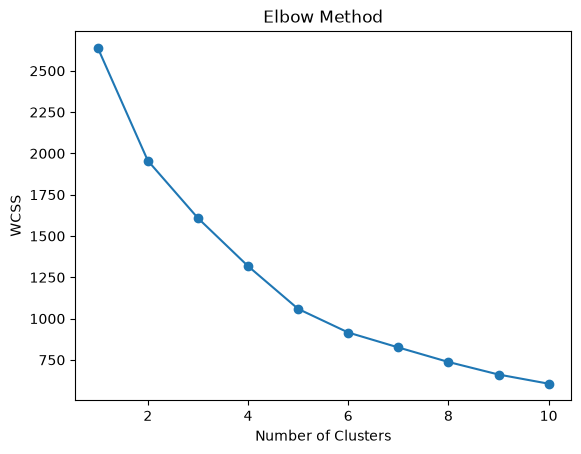

{2: 0.5472146913441881, 3: 0.5482872649700601, 4: 0.34847138657014315, 5: 0.3690403826812808, 6: 0.3782288965882046, 7: 0.3342819788182625, 8: 0.3201161896109077, 9: 0.30902833452574485, 10: 0.3112143583568513}
best_k: 3


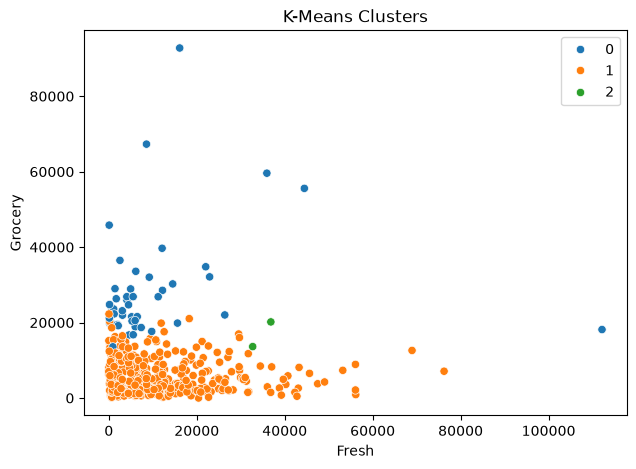

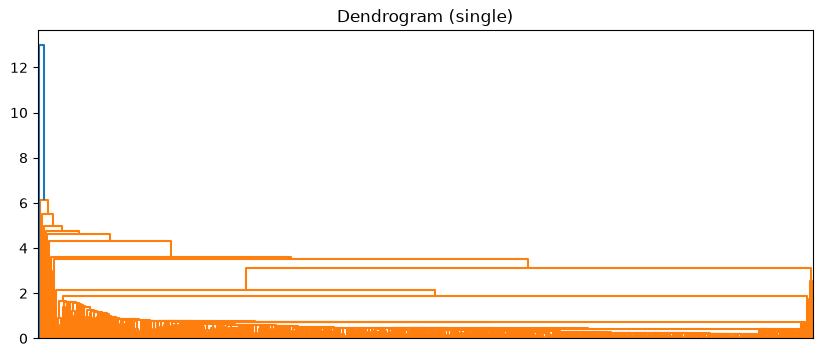

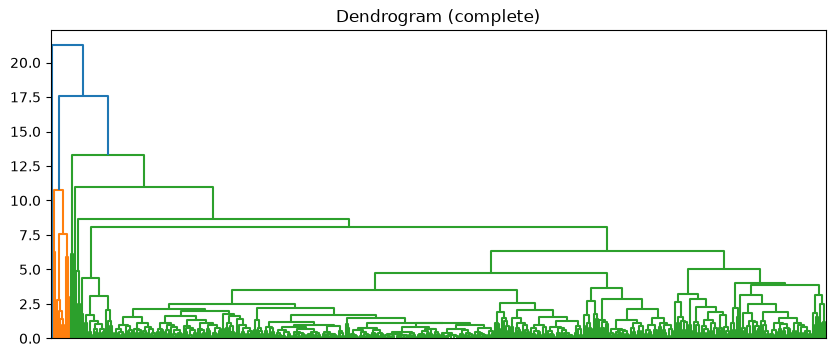

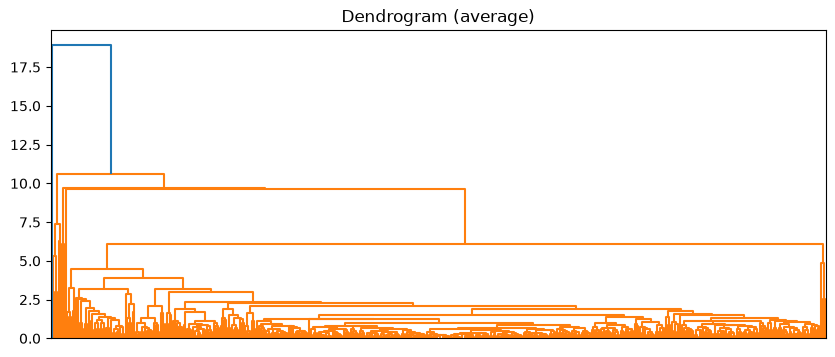

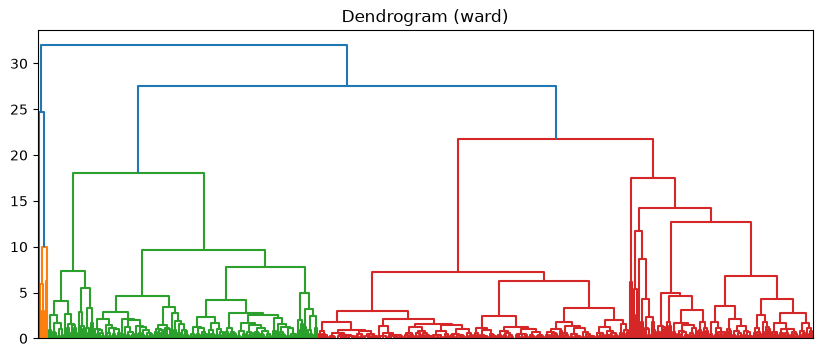

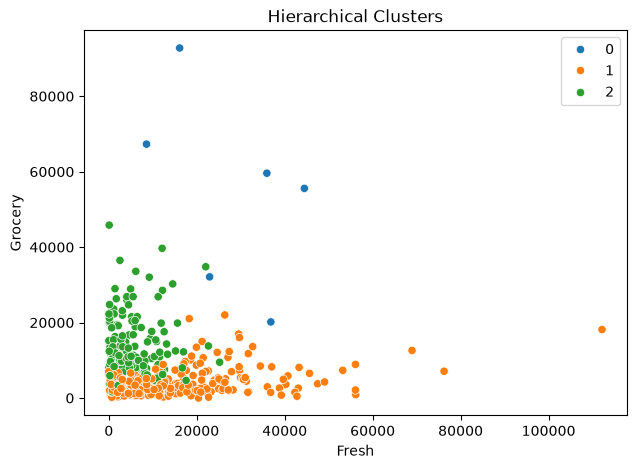

                       Fresh          Milk       Grocery        Frozen  \
KMeans_Cluster                                                           
0               10440.933333  19386.422222  28656.088889   2190.244444   
1               12062.913486   4115.099237   5534.966921   2940.676845   
2               34782.000000  30367.000000  16898.000000  48701.500000   

                Detergents_Paper    Delicassen  
KMeans_Cluster                                  
0                   13327.800000   2374.200000  
1                    1696.170483   1299.114504  
2                     755.500000  26776.000000  
                   Fresh          Milk       Grocery       Frozen  \
HC_Cluster                                                          
0           27477.000000  43542.166667  54588.500000  8285.666667   
1           15048.932384   3017.298932   3791.761566  3837.316726   
2            5794.241830   9419.888889  13761.738562  1461.764706   

            Detergents_Paper    Delica

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Load Dataset
df = pd.read_csv("Wholesale customers data.csv")

print(df.head())
print("Shape:", df.shape)
print(df.dtypes)
print(df.isnull().sum())

# 2. Select Numerical Features
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = df[features]

# Apply median imputation for missing values
X = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X), columns=features)

# 3. Feature Scaling
X_scaled = StandardScaler().fit_transform(X)

# 4. Elbow Method
wcss = []

for k in range(1, 11):
    wcss.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 5. Silhouette Score
scores = {}

for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

print(scores)

best_k = max(scores, key=scores.get)
print("best_k:", best_k)

# 6. K-Means
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)

# 7. Visualization
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X['Fresh'], y=X['Grocery'], hue=km_labels, palette='tab10')
plt.title("K-Means Clusters")
plt.show()

# 8. Dendrogram
methods = ['single', 'complete', 'average', 'ward']

for method in methods:
    plt.figure(figsize=(10, 4))
    dendrogram(linkage(X_scaled, method=method), no_labels=True)
    plt.title(f"Dendrogram ({method})")
    plt.show()

# 9. Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)

# 10. Visualization
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X['Fresh'], y=X['Grocery'], hue=hc_labels, palette='tab10')
plt.title("Hierarchical Clusters")
plt.show()

# 11. Cluster Interpretation
result = X.copy()
result['KMeans_Cluster'] = km_labels
result['HC_Cluster'] = hc_labels
result['Channel'] = df['Channel']
result['Region'] = df['Region']

print(result.groupby('KMeans_Cluster')[features].mean())
print(result.groupby('HC_Cluster')[features].mean())
print(result['KMeans_Cluster'].value_counts().sort_index())
print(result['HC_Cluster'].value_counts().sort_index())
print(pd.crosstab(result['KMeans_Cluster'], result['Channel']))
print(pd.crosstab(result['KMeans_Cluster'], result['Region']))
print(pd.crosstab(result['HC_Cluster'], result['Channel']))
print(pd.crosstab(result['HC_Cluster'], result['Region']))

# 12. Comparison
km_score = silhouette_score(X_scaled, km_labels)
hc_score = silhouette_score(X_scaled, hc_labels)

print("K-Means:", km_score)
print("Hierarchical:", hc_score)

### Task 1: Analysis

- **Selected K:** K = 3 (highest silhouette score, 0.548; the elbow also flattens around 3).
- **Higher-spending groups:** K-Means cluster 0 (45 customers) spends heavily on Milk, Grocery and Detergents_Paper, and Channel 2 (Retail) makes up nearly all of it (44 of 45). Cluster 2 (only 2 customers) is made up of extreme outliers with very high Frozen, Fresh, Milk and Delicassen spending. Cluster 1 (393 customers) is the large low-to-moderate spending group. In the hierarchical result, cluster 0 (6 customers) is the very-high spender group, cluster 2 (153) is a mid-spending, Grocery/Milk/Detergents-heavy retail group, and cluster 1 (281) buys mostly Fresh and is mostly Channel 1 (Horeca).
- **K-Means vs Hierarchical:** K-Means produced one big cluster plus a small group and two outlier customers (sizes 393/45/2). Ward hierarchical clustering produced more balanced groups (281/153/6) that line up better with the Channel split. Both are affected by the heavily skewed spending data, so a few outliers form their own groups.
- **Better separation:** K-Means has the higher silhouette score (0.548 vs 0.265), so it gives better-separated clusters by that metric. Most of that score comes from isolating the outliers.
- **Marketing use:** Offer volume discounts and bundled Grocery/Milk/Detergent deals to the high-spending retail group. Offer fresh-produce subscription and delivery plans to the Fresh-heavy Horeca group. Give the few very large accounts a dedicated account manager and custom contracts. Use cross-selling for the low spenders to raise their basket size. Channel and Region were not used for clustering, but the clusters align strongly with Channel, so the segments match real business categories.

### TASK 2: DRY BEAN VARIETY GROUPING

    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272750  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358      0.007332  

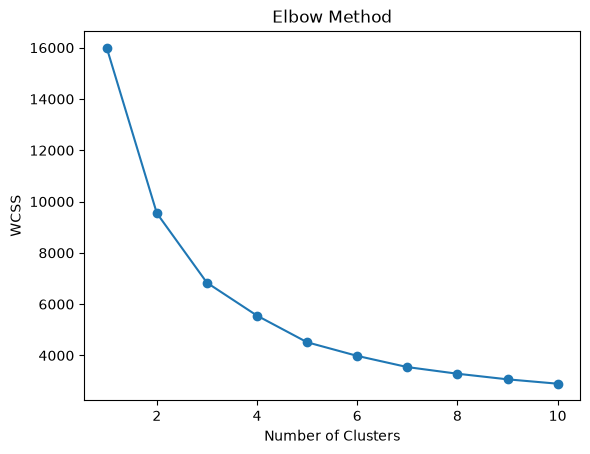

{2: 0.3935530274055925, 3: 0.40197862562319553, 4: 0.3314974885398892, 5: 0.34210458019663237, 6: 0.3008223892339478, 7: 0.30813586957228356, 8: 0.30086613639291887, 9: 0.30103981705078536, 10: 0.28852291067202007}
best_k: 3


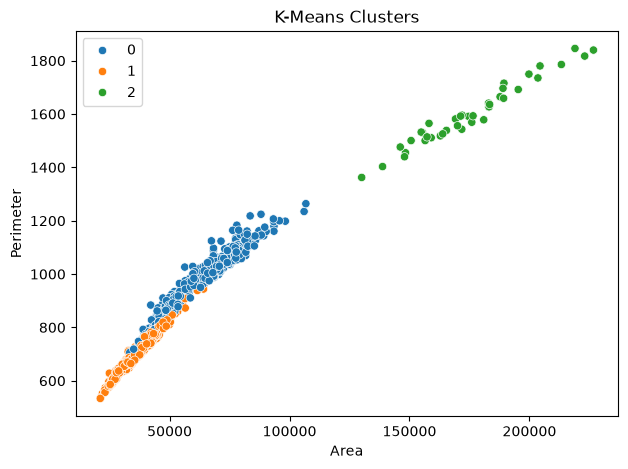

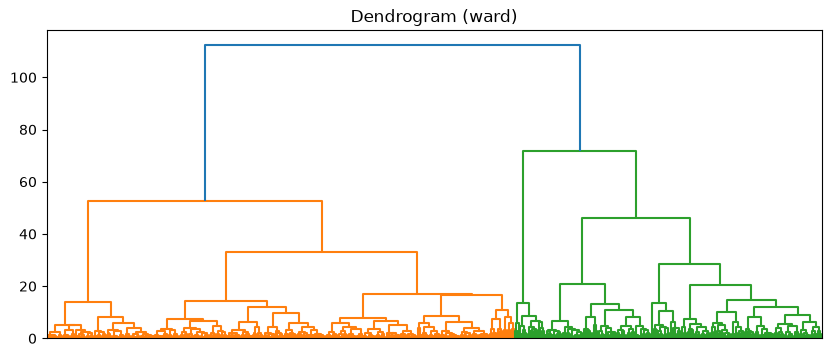

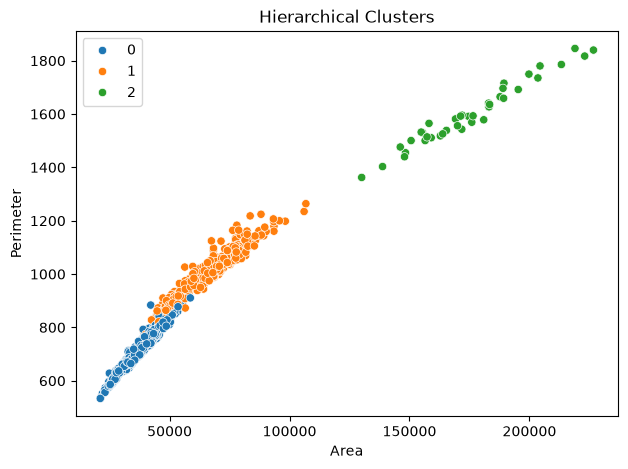

K-Means: 0.40197862562319553
Hierarchical: 0.3993751614950837
                         Area    Perimeter  MajorAxisLength  MinorAxisLength  \
KMeans_Cluster                                                                 
0                63066.922306   979.733805       378.402165       212.163828   
1                38019.340463   720.307086       262.860892       183.376083   
2               175766.325000  1602.118350       598.485482       376.121433   

                AspectRation  Eccentricity     ConvexArea  EquivDiameter  \
KMeans_Cluster                                                             
0                   1.804192      0.822906   64026.786967     281.778777   
1                   1.440341      0.704602   38441.092692     218.934440   
2                   1.591389      0.772937  178376.175000     472.083309   

                  Extent  Solidity  roundness  Compactness  ShapeFactor1  \
KMeans_Cluster                                                             
0   

In [2]:
# 1. Load Dataset
df2 = pd.read_excel("Dry_Bean_Dataset.xlsx")

print(df2.head())
print("Shape:", df2.shape)
print(df2.dtypes)
print(df2.isnull().sum())

# 2. Select Numerical Features
# Exclude Class from clustering
features = df2.drop(columns='Class').select_dtypes(include='number').columns.tolist()
print(features)

# 3. Random Sample
sample = df2.sample(n=1000, random_state=42).reset_index(drop=True)
X = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(sample[features]), columns=features)

# 4. Feature Scaling
X_scaled = StandardScaler().fit_transform(X)

# 5. Elbow Method
wcss = []

for k in range(1, 11):
    wcss.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 6. Silhouette Score
scores = {}

for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

print(scores)
best_k = max(scores, key=scores.get)
print("best_k:", best_k)

# 7. K-Means
km_labels = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X_scaled)

# 8. Visualization
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X['Area'], y=X['Perimeter'], hue=km_labels, palette='tab10')
plt.title("K-Means Clusters")
plt.show()

# 9. Dendrogram
plt.figure(figsize=(10, 4))
dendrogram(linkage(X_scaled, method='ward'), no_labels=True)
plt.title("Dendrogram (ward)")
plt.show()

# 10. Hierarchical Clustering
hc_labels = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_scaled)

# 11. Visualization
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X['Area'], y=X['Perimeter'], hue=hc_labels, palette='tab10')
plt.title("Hierarchical Clusters")
plt.show()

# 12. Silhouette Score Comparison
km_score = silhouette_score(X_scaled, km_labels)
hc_score = silhouette_score(X_scaled, hc_labels)
print("K-Means:", km_score)
print("Hierarchical:", hc_score)

# 13. Cluster Characteristics
result = X.copy()
result['KMeans_Cluster'] = km_labels
result['HC_Cluster'] = hc_labels
result['Class'] = sample['Class']

print(
    result.groupby('KMeans_Cluster')[features].mean()
)
print(result['KMeans_Cluster'].value_counts().sort_index())
print(result['HC_Cluster'].value_counts().sort_index())

# 14. Actual Class Comparison
print(pd.crosstab(result['KMeans_Cluster'], result['Class']))
print(pd.crosstab(result['HC_Cluster'], result['Class']))

### Task 2: Analysis

- **Selected K:** K = 3 (highest silhouette score, 0.402).
- **Distinguishing characteristics:** Size features separate the groups most clearly: Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea and EquivDiameter. Cluster 2 (40 beans) is the largest by far (mean Area about 175,766). Cluster 0 is medium-sized and more elongated (higher AspectRation and Eccentricity, lower roundness and Compactness). Cluster 1 is the smallest and roundest (highest roundness, Compactness and ShapeFactor values).
- **Correspondence to actual varieties:** Only partly. Cluster 2 corresponds exactly to the BOMBAY variety (all 40). The other two clusters mix varieties: cluster 0 contains Barbunya, Cali and Horoz together with some Sira, and cluster 1 contains Dermason, Seker and Sira. Similar-sized and similar-shaped varieties overlap, so with k=3 the clusters group beans by general size and shape rather than by exact variety.
- **K-Means vs Hierarchical:** Both found a very similar structure, including the same Bombay cluster. They differ mainly in how they split the two remaining groups (399/561 for K-Means vs 356/604 for Ward) and in which borderline beans (mostly Sira, Barbunya and Dermason) go where.
- **Better separation:** K-Means is marginally better (0.4020 vs 0.3994), which is practically a tie.

### TASK 3: WINE PRODUCT PROFILING

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

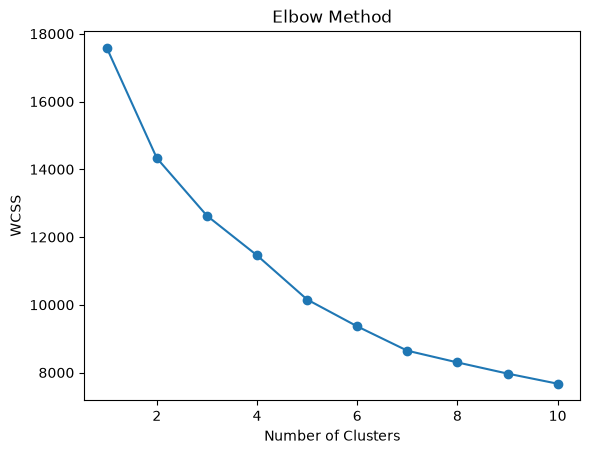

{2: 0.2137299633550709, 3: 0.18920406811092624, 4: 0.17163618556172924, 5: 0.1901392066362046, 6: 0.19472922935137707, 7: 0.19259125768459864, 8: 0.1495079628059986, 9: 0.1534388568930887, 10: 0.1573800019000426}
best_k: 2


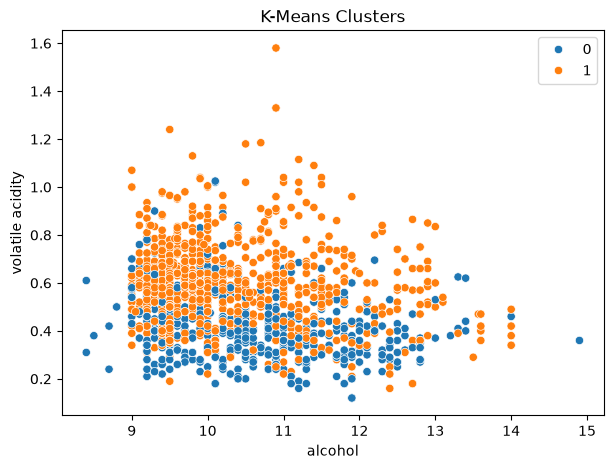

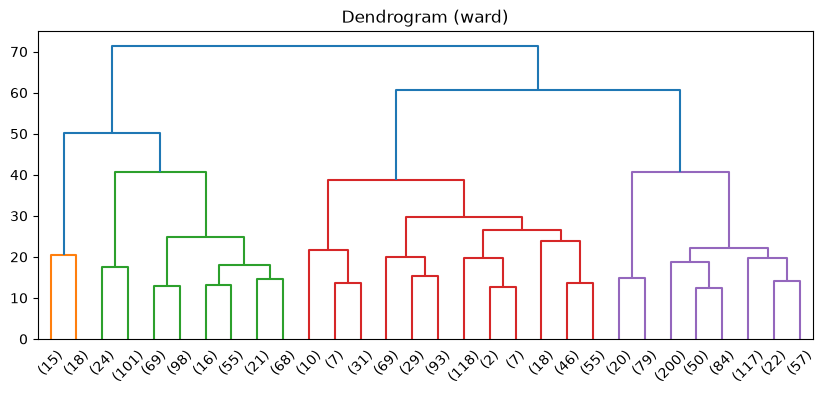

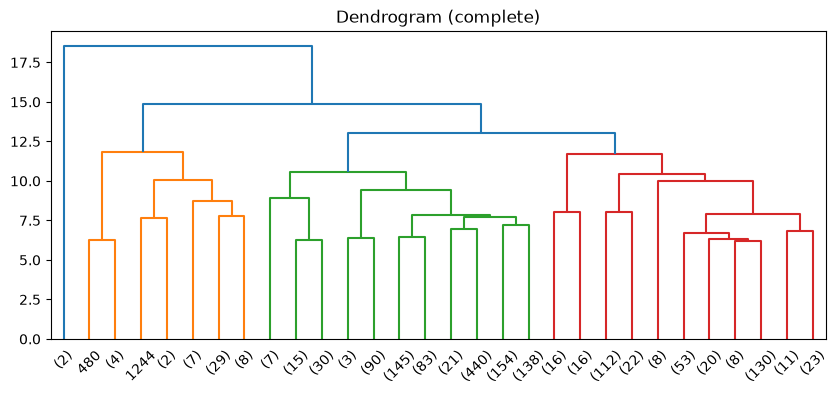

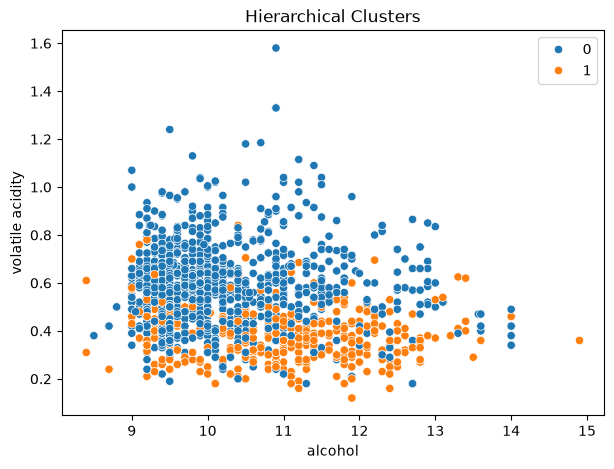

                fixed acidity  volatile acidity  citric acid  residual sugar  \
KMeans_Cluster                                                                 
0                    9.922712          0.413907     0.462881        2.765763   
1                    7.382260          0.594430     0.158761        2.406095   

                chlorides  free sulfur dioxide  total sulfur dioxide  \
KMeans_Cluster                                                         
0                0.099900            13.410169             39.388136   
1                0.080196            17.316155             50.607532   

                 density        pH  sulphates    alcohol  
KMeans_Cluster                                            
0               0.997689  3.201847   0.748237  10.607401  
1               0.996195  3.375005   0.605471  10.315147  
            fixed acidity  volatile acidity  citric acid  residual sugar  \
HC_Cluster                                                                 
0 

In [3]:
# 1. Load Dataset
df3 = pd.read_csv("winequality-red.csv", sep=';')

print(df3.head())
print(df3.shape)
print(df3.dtypes)
print(df3.isnull().sum())

# 2. Select Numerical Features
# Exclude quality from clustering

features = [
    'fixed acidity',
    'volatile acidity',
    'citric acid',
    'residual sugar',
    'chlorides',
    'free sulfur dioxide',
    'total sulfur dioxide',
    'density',
    'pH',
    'sulphates',
    'alcohol'
]

# apply median imputation for missing values
X = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(df3[features]), columns=features)

# 3. Feature Scaling
X_scaled = StandardScaler().fit_transform(X)

# 4. Elbow Method
wcss = []

for k in range(1, 11):
    wcss.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 5. Silhouette Score
scores = {}

for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

print(scores)
best_k = max(scores, key=scores.get)
print("best_k:", best_k)

# 6. K-Means Clustering
km_labels = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X_scaled)

# 7. Visualization
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X['alcohol'], y=X['volatile acidity'], hue=km_labels, palette='tab10')
plt.title("K-Means Clusters")
plt.show()

# 8. Dendrograms
methods = ['ward', 'complete']

for method in methods:
    plt.figure(figsize=(10, 4))
    dendrogram(linkage(X_scaled, method=method), truncate_mode='lastp', p=30)
    plt.title(f"Dendrogram ({method})")
    plt.show()

# 9. Hierarchical Clustering
hc_labels = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_scaled)

# 10. Visualization
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X['alcohol'], y=X['volatile acidity'], hue=hc_labels, palette='tab10')
plt.title("Hierarchical Clusters")
plt.show()

# 11. Chemical Characteristics
result = X.copy()
result['KMeans_Cluster'] = km_labels
result['HC_Cluster'] = hc_labels
result['quality'] = df3['quality']

print(result.groupby('KMeans_Cluster')[features].mean())
print(result.groupby('HC_Cluster')[features].mean())
print(result['KMeans_Cluster'].value_counts().sort_index())
print(result['HC_Cluster'].value_counts().sort_index())

# 12. Quality Interpretation
print(result.groupby('KMeans_Cluster')['quality'].agg(['mean', 'count']))
print(result.groupby('HC_Cluster')['quality'].agg(['mean', 'count']))

# 13. Compare Algorithms
from sklearn.metrics import davies_bouldin_score

km_score = silhouette_score(X_scaled, km_labels)
hc_score = silhouette_score(X_scaled, hc_labels)

print("K-Means:", km_score)
print("Hierarchical:", hc_score)
print("Davies-Bouldin K-Means:", davies_bouldin_score(X_scaled, km_labels))
print("Davies-Bouldin Hierarchical:", davies_bouldin_score(X_scaled, hc_labels))

### Task 3: Analysis

- **Selected K:** K = 2 (highest silhouette score, 0.214). Scores are low overall, so the wine data has weak cluster structure.
- **Distinguishing chemical properties:** One K-Means group has higher fixed acidity, citric acid, density, chlorides, sulphates and alcohol and lower pH and volatile acidity. The other has lower fixed acidity and citric acid, higher volatile acidity and sulfur dioxide levels, and higher pH. The Ward hierarchical groups show the same pattern, with the larger sulfur dioxide-heavy group at lower alcohol.
- **Quality differences:** Yes, but modestly. The K-Means group with higher acidity, sulphates and alcohol has a higher average quality (5.89 vs 5.48). For Ward, the group with more alcohol, citric acid and sulphates has the higher average quality (6.07 vs 5.45). Higher alcohol, sulphates and citric acid with lower volatile acidity are associated with better quality.
- **K-Means vs Hierarchical:** The two methods find similar chemical profiles but draw the boundary differently. K-Means gives a 590/1009 split and Ward gives 1114/485.
- **Better separation:** K-Means has the higher Silhouette Score (0.214 vs 0.183) and the lower Davies-Bouldin Index (1.871 vs 2.030, lower is better), so it gives better-separated clusters on both metrics.